# Mini-Projet 02 : Reconnaissance de variétés de haricots
**INSEA · Cours de Machine Learning · 2026-2027**

**Ma partie : Arbre de Décision (Gini, tuning `max_depth`) et Random Forest (tuning `n_estimators`, `max_depth`)**

## Règle d'or commune à l'équipe
| Élément | Choix |
|---|---|
| Dataset | UCI Dry Bean (13 611 lignes, 16 variables, 7 classes) |
| Seed | `random_state = 42` partout (split, CV, modèles) |
| Split | 80/20 stratifié (`stratify=y`) |
| Standardisation | `Pipeline` avec `StandardScaler` (aucune fuite de données) |
| Validation croisée | `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sur le train uniquement |
| Métrique principale | **Macro F1-score** |

## Plan du notebook
0. Configuration et imports
1. Chargement des données
2. Exploration (variables, classes, valeurs manquantes, graphiques)
3. Séparation train / test
4. Pipelines et expérience de standardisation
5. Arbre de décision : GridSearchCV
6. Random Forest : GridSearchCV
7. Évaluation finale sur le test (une seule fois)
8. Comparaison des modèles et confusions
9. Importance des variables
10. Synthèse et export des résultats

## 0. Configuration et imports

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

SEED = 42   # seed universelle de l'équipe

## 1. Chargement des données
Le jeu de données est téléchargé depuis le dépôt UCI (id 602). Si le téléchargement échoue (pas d'internet), on lit le fichier Excel `Dry_Bean_Dataset.xlsx` placé dans le même dossier que le notebook.

In [23]:
# Installation si nécessaire :  pip install ucimlrepo openpyxl
try:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=602)
    X = ds.data.features.copy()
    y = ds.data.targets.squeeze().copy()
except Exception as e:
    print("ucimlrepo indisponible, lecture du fichier local :", e)
    df_local = pd.read_excel("Dry_Bean_Dataset.xlsx")
    X, y = df_local.drop(columns="Class"), df_local["Class"]

y.name = "Class"
df = pd.concat([X, y], axis=1)
print("Dimensions de X :", X.shape)
print("Classes :", sorted(y.unique()))
df.head()

Dimensions de X : (13611, 16)
Classes : ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Exploration des données
### 2.1 Description des 16 variables et valeurs manquantes

In [3]:
display(X.dtypes.to_frame("type").T)
display(X.describe().T.round(3))
print("Valeurs manquantes (total) :", int(X.isna().sum().sum()))
print("Lignes dupliquées          :", int(X.duplicated().sum()))

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
type,int64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.523,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRation,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


Valeurs manquantes (total) : 0
Lignes dupliquées          : 68


### 2.2 Répartition des sept classes

,effectif,proportion (%)
Class,,
DERMASON,3546,26.05
SIRA,2636,19.37
SEKER,2027,14.89
HOROZ,1928,14.17
CALI,1630,11.98
BARBUNYA,1322,9.71
BOMBAY,522,3.84


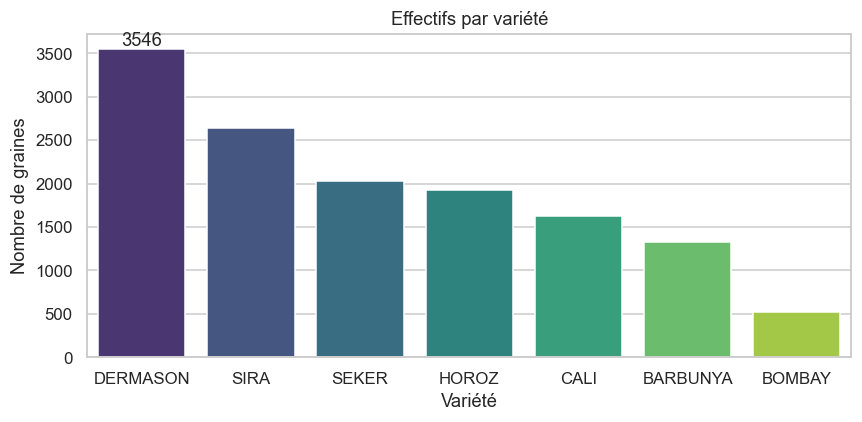

In [4]:
counts = y.value_counts()
display(pd.DataFrame({"effectif": counts, "proportion (%)": (counts / len(y) * 100).round(2)}))

plt.figure(figsize=(8, 4))
ax = sns.countplot(x=y, order=counts.index, palette="viridis")
ax.bar_label(ax.containers[0])
plt.title("Effectifs par variété")
plt.xlabel("Variété"); plt.ylabel("Nombre de graines")
plt.tight_layout(); plt.show()

### 2.3 Distributions de caractéristiques morphologiques

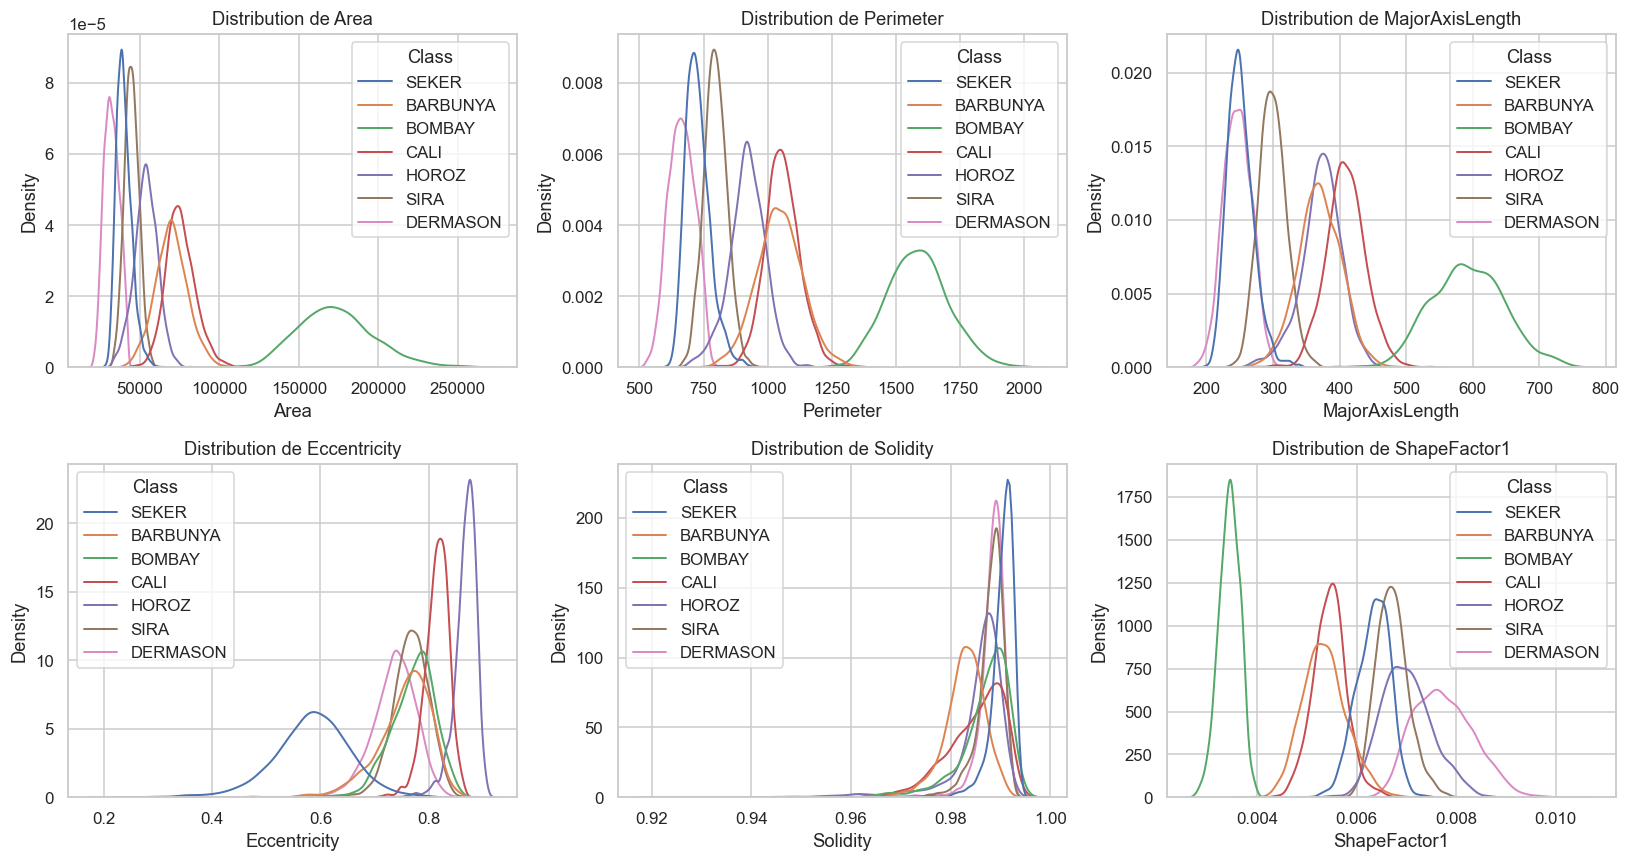

In [5]:
feats = ["Area", "Perimeter", "MajorAxisLength", "Eccentricity", "Solidity", "ShapeFactor1"]
feats = [f for f in feats if f in X.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), feats):
    sns.kdeplot(data=df, x=f, hue="Class", common_norm=False, ax=ax, fill=False, linewidth=1.3)
    ax.set_title(f"Distribution de {f}")
plt.tight_layout(); plt.show()

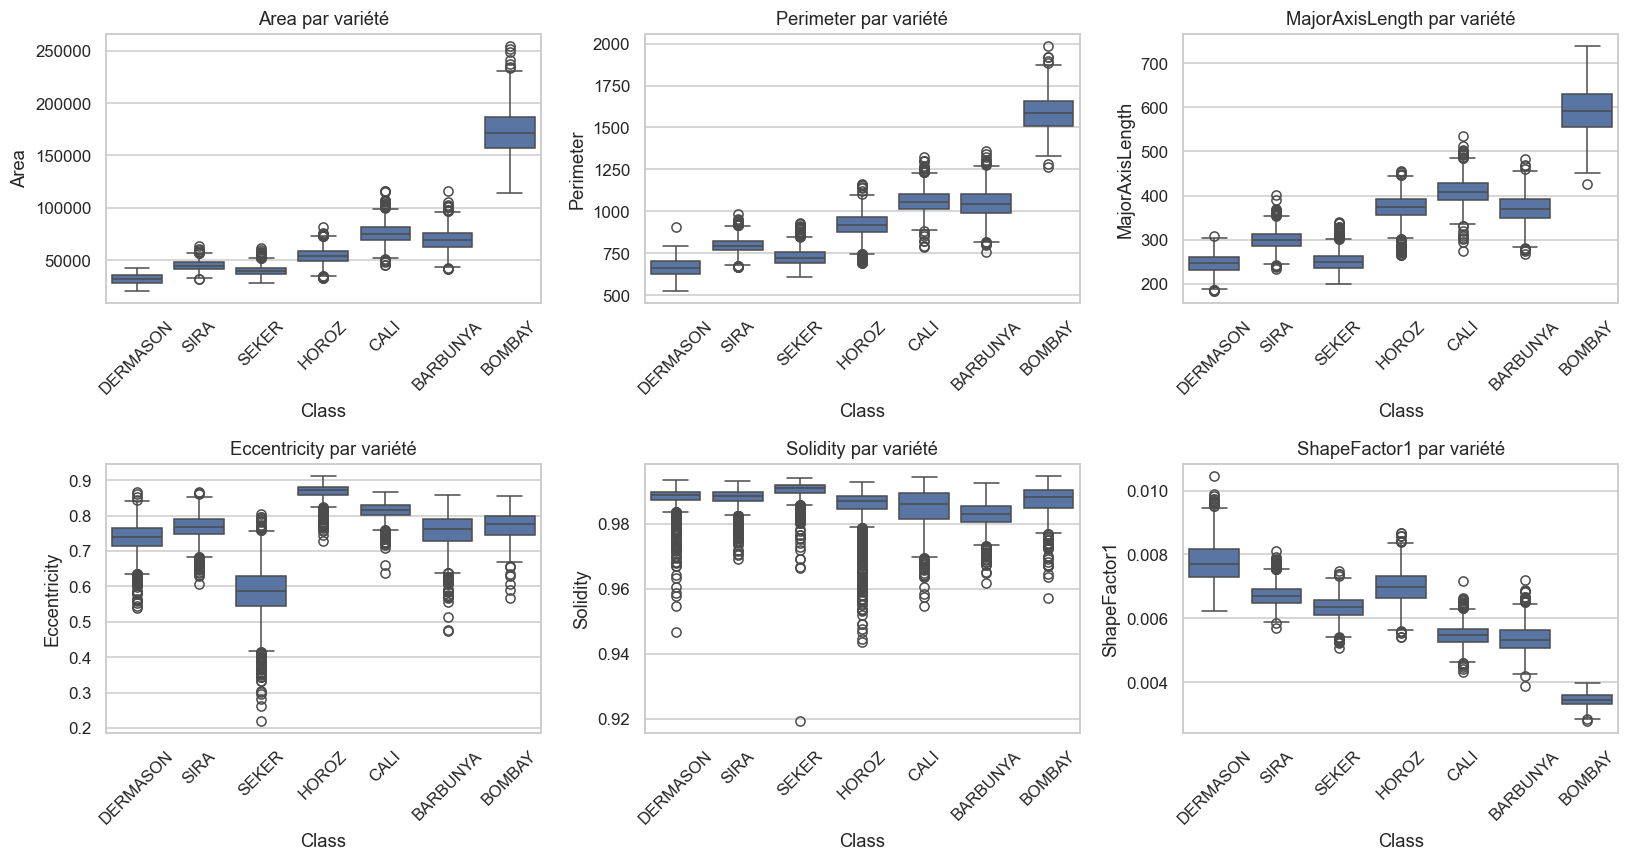

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), feats):
    sns.boxplot(data=df, x="Class", y=f, ax=ax, order=counts.index)
    ax.set_title(f"{f} par variété")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### 2.4 Corrélations entre variables
Beaucoup de variables sont fortement corrélées (Area, ConvexArea, EquivDiameter, Perimeter…). Cela ne gêne pas les arbres, mais il faut en tenir compte pour interpréter l'importance des variables.

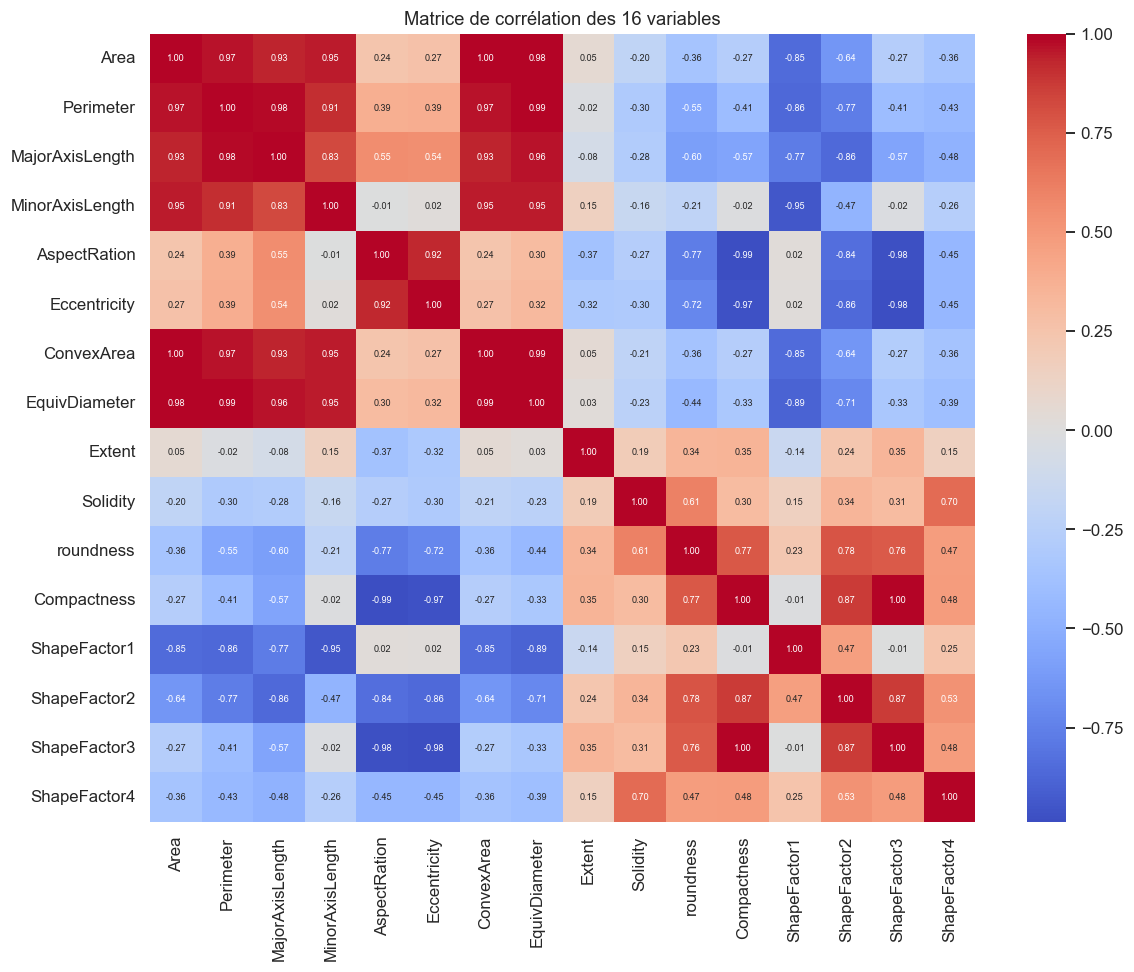

In [7]:
plt.figure(figsize=(11, 9))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 6})
plt.title("Matrice de corrélation des 16 variables")
plt.tight_layout(); plt.show()

## 3. Séparation train / test
Split 80/20 **stratifié** (mêmes proportions des 7 variétés dans le train et le test), avec la seed commune. Le jeu de test ne sera utilisé qu'à la section 7.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train :", X_train.shape, "| Test :", X_test.shape)
prop = pd.DataFrame({
    "global (%)": y.value_counts(normalize=True) * 100,
    "train (%)": y_train.value_counts(normalize=True) * 100,
    "test (%)": y_test.value_counts(normalize=True) * 100,
}).round(2)
prop

Train : (10888, 16) | Test : (2723, 16)


,global (%),train (%),test (%)
Class,,,
DERMASON,26.05,26.06,26.04
SIRA,19.37,19.37,19.35
SEKER,14.89,14.89,14.91
HOROZ,14.17,14.16,14.18
CALI,11.98,11.98,11.97
BARBUNYA,9.71,9.71,9.73
BOMBAY,3.84,3.84,3.82


## 4. Pipelines et expérience de standardisation
La fonction `make_pipe` construit un `Pipeline` avec ou sans `StandardScaler`. Utilisé dans une validation croisée, le scaler est recalculé sur les plis d'apprentissage uniquement, donc **aucune fuite de données**.

**Hypothèse théorique** : un arbre de décision coupe selon des seuils `x_j <= s` qui ne dépendent que de l'**ordre** des valeurs. La standardisation étant une transformation affine croissante, elle ne change pas cet ordre, donc les arbres (et les forêts) ne sont **pas sensibles à l'échelle**. Les scores avec et sans scaler doivent être identiques ou quasi identiques.

Cette comparaison se fait en **validation croisée sur le train** (le test n'est jamais utilisé).

In [9]:
def make_pipe(model, scale=True):
    steps = ([("scaler", StandardScaler())] if scale else []) + [("clf", model)]
    return Pipeline(steps)

def new_dt(**kw):
    return DecisionTreeClassifier(criterion="gini", random_state=SEED, **kw)

def new_rf(**kw):
    return RandomForestClassifier(random_state=SEED, n_jobs=-1, **kw)

In [10]:
rows, raw_scores = [], {}
for name, mk in [("Arbre de décision", new_dt), ("Random Forest", new_rf)]:
    for scale in (False, True):
        s = cross_val_score(make_pipe(mk(), scale), X_train, y_train,
                            cv=cv, scoring="f1_macro", n_jobs=-1)
        raw_scores[(name, scale)] = s
        rows.append({"Modèle": name,
                     "Standardisation": "Oui" if scale else "Non",
                     "F1 macro CV (moy.)": round(s.mean(), 4),
                     "Écart-type": round(s.std(), 4)})

std_table = pd.DataFrame(rows)
display(std_table)

for name in ["Arbre de décision", "Random Forest"]:
    same = np.allclose(raw_scores[(name, False)], raw_scores[(name, True)])
    print(f"{name} : scores identiques avec/sans scaler ? {same}")

,Modèle,Standardisation,F1 macro CV (moy.),Écart-type
0,Arbre de décision,Non,0.9104,0.0021
1,Arbre de décision,Oui,0.9101,0.0028
2,Random Forest,Non,0.9358,0.0047
3,Random Forest,Oui,0.9354,0.0048


Arbre de décision : scores identiques avec/sans scaler ? False
Random Forest : scores identiques avec/sans scaler ? False


**Interprétation** : si les scores sont identiques, cela confirme que les modèles à base d'arbres sont invariants aux changements d'échelle monotones. Contrairement à KNN, SVM ou à la régression logistique, la standardisation n'apporte ici aucun gain. Elle est conservée dans le pipeline pour rester compatible avec le setup de l'équipe.

## 5. Arbre de décision : GridSearchCV
Critère fixé à **Gini**. On cherche `max_depth` en maximisant le **F1 macro** sur 5 plis stratifiés. `return_train_score=True` permet d'étudier le sur-apprentissage.

In [11]:
param_grid_dt = {"clf__max_depth": [3, 5, 7, 9, 11, 13, 15, None]}

grid_dt = GridSearchCV(
    make_pipe(new_dt(), scale=True),
    param_grid_dt,
    cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True
)
grid_dt.fit(X_train, y_train)

print("Meilleurs paramètres :", grid_dt.best_params_)
print(f"Meilleur F1 macro CV : {grid_dt.best_score_:.4f}")

Meilleurs paramètres : {'clf__max_depth': 9}
Meilleur F1 macro CV : 0.9211


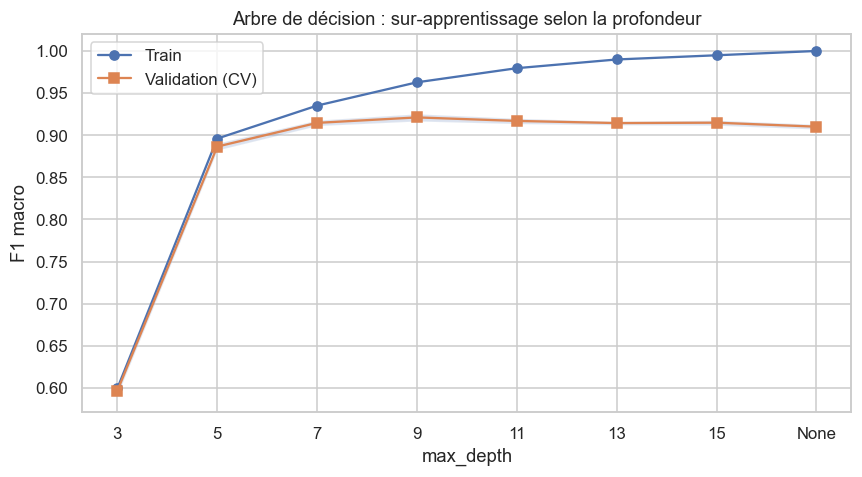

,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,{'clf__max_depth': 3},0.5993,0.5964,0.0048,8
1,{'clf__max_depth': 5},0.8960,0.8865,0.0041,7
2,{'clf__max_depth': 7},0.9351,0.9146,0.0033,4
3,{'clf__max_depth': 9},0.9628,0.9211,0.0043,1
4,{'clf__max_depth': 11},0.9796,0.9169,0.0032,2
5,{'clf__max_depth': 13},0.9899,0.9144,0.0021,5
6,{'clf__max_depth': 15},0.9949,0.9148,0.0030,3
7,{'clf__max_depth': None},1.0000,0.9101,0.0028,6


In [12]:
res_dt = pd.DataFrame(grid_dt.cv_results_)
labels = [str(p["clf__max_depth"]) for p in res_dt["params"]]

plt.figure(figsize=(8, 4.5))
plt.plot(labels, res_dt["mean_train_score"], "o-", label="Train")
plt.plot(labels, res_dt["mean_test_score"], "s-", label="Validation (CV)")
plt.fill_between(labels,
                 res_dt["mean_test_score"] - res_dt["std_test_score"],
                 res_dt["mean_test_score"] + res_dt["std_test_score"], alpha=0.2)
plt.xlabel("max_depth"); plt.ylabel("F1 macro")
plt.title("Arbre de décision : sur-apprentissage selon la profondeur")
plt.legend(); plt.tight_layout(); plt.show()

res_dt[["params", "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].round(4)

**À commenter** : l'écart entre la courbe train et la courbe validation grandit avec la profondeur (sur-apprentissage). La profondeur retenue correspond au meilleur compromis biais / variance.

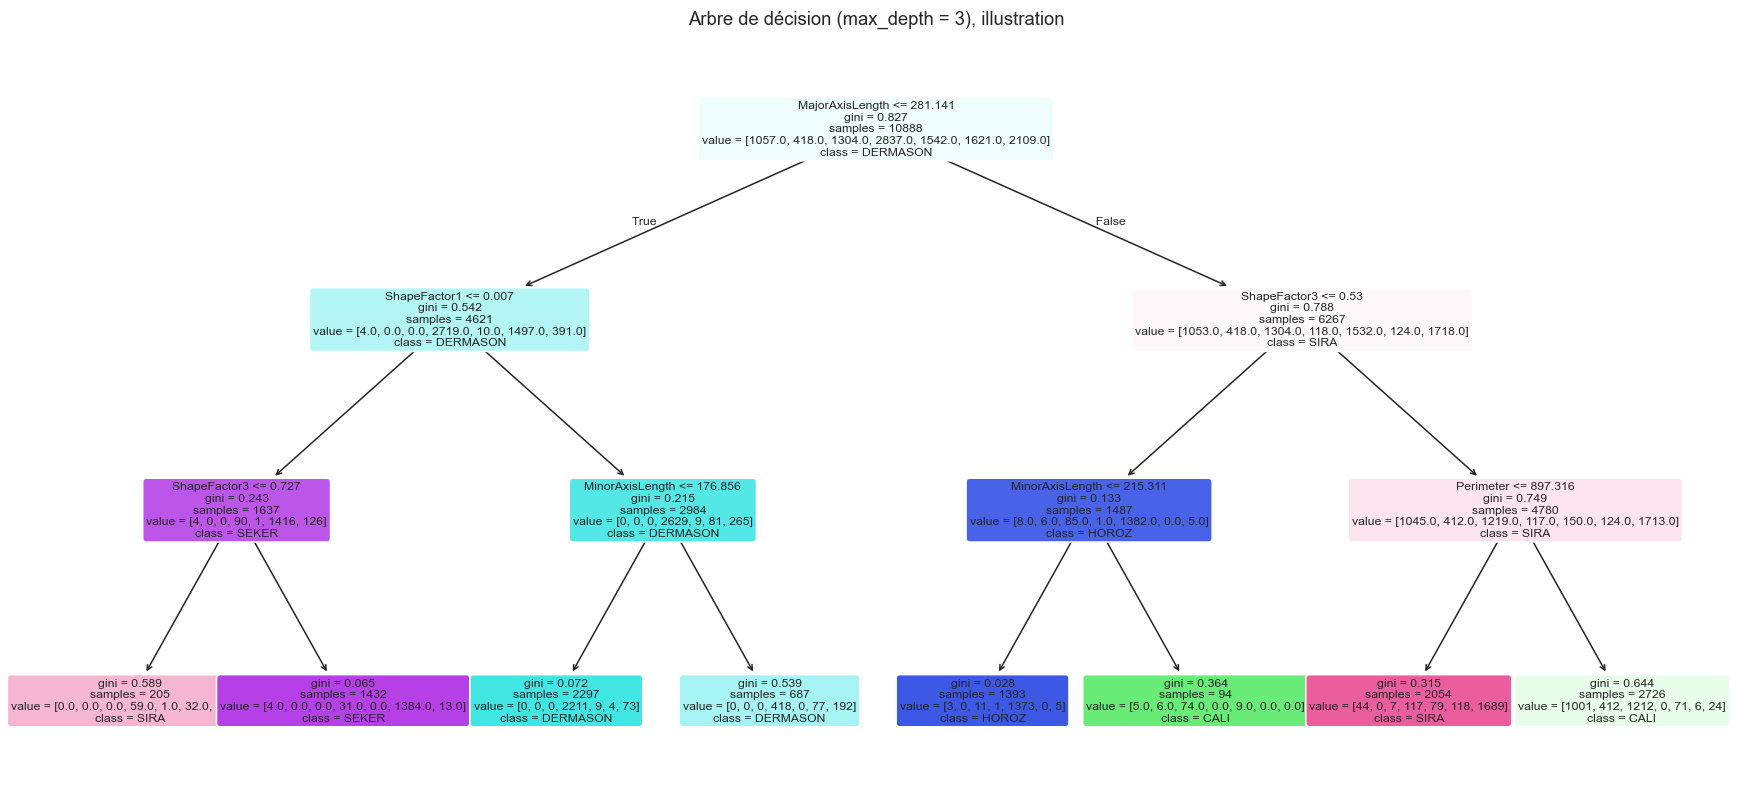

In [13]:
# Visualisation d'un arbre simple (profondeur 3) pour l'interprétabilité
small_tree = new_dt(max_depth=3).fit(X_train, y_train)
plt.figure(figsize=(20, 9))
plot_tree(small_tree, feature_names=list(X.columns), class_names=list(small_tree.classes_),
          filled=True, rounded=True, fontsize=8)
plt.title("Arbre de décision (max_depth = 3), illustration")
plt.show()

## 6. Random Forest : GridSearchCV
Hyperparamètres : `n_estimators` et `max_depth`. La grille contient 16 combinaisons × 5 plis = 80 entraînements (quelques minutes selon la machine).

In [14]:
param_grid_rf = {
    "clf__n_estimators": [100, 200, 300, 500],
    "clf__max_depth": [10, 15, 20, None],
}

grid_rf = GridSearchCV(
    make_pipe(new_rf(), scale=True),
    param_grid_rf,
    cv=cv, scoring="f1_macro", n_jobs=1, return_train_score=True, verbose=1
)
grid_rf.fit(X_train, y_train)

print("Meilleurs paramètres :", grid_rf.best_params_)
print(f"Meilleur F1 macro CV : {grid_rf.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Meilleurs paramètres : {'clf__max_depth': None, 'clf__n_estimators': 200}
Meilleur F1 macro CV : 0.9363


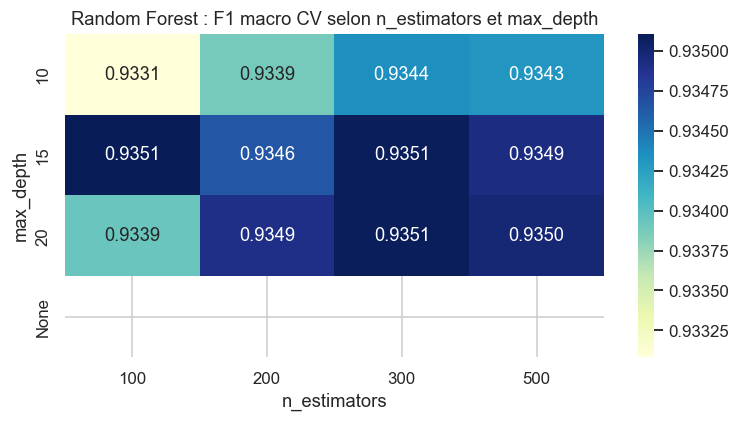

In [15]:
res_rf = pd.DataFrame(grid_rf.cv_results_)
res_rf["n_estimators"] = res_rf["param_clf__n_estimators"].astype(int)
res_rf["max_depth"] = res_rf["param_clf__max_depth"].astype(str)

pivot = res_rf.pivot(index="max_depth", columns="n_estimators", values="mean_test_score")
pivot = pivot.reindex(["10", "15", "20", "None"])

plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="YlGnBu")
plt.title("Random Forest : F1 macro CV selon n_estimators et max_depth")
plt.tight_layout(); plt.show()

**À commenter** : le gain en augmentant `n_estimators` plafonne rapidement (plus d'arbres réduit la variance sans provoquer de sur-apprentissage, mais coûte du temps de calcul). `max_depth` a un effet plus faible que pour l'arbre seul, car le bagging corrige une partie de la variance.

## 7. Évaluation finale sur le test (une seule fois)
⚠️ Cette section est la **seule** qui utilise `X_test`. Les modèles retenus sont les `best_estimator_` des deux GridSearchCV. On ne revient pas modifier les hyperparamètres après avoir vu ces résultats.

In [16]:
classes = sorted(y.unique())
final_models = {"Arbre de décision": grid_dt.best_estimator_,
                "Random Forest": grid_rf.best_estimator_}

results, per_class, cms = {}, {}, {}
for name, model in final_models.items():
    y_pred = model.predict(X_test)
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted"),
    }
    rep = classification_report(y_test, y_pred, output_dict=True, digits=4)
    per_class[name] = pd.DataFrame(rep).T.loc[classes + ["macro avg"]]
    cms[name] = confusion_matrix(y_test, y_pred, labels=classes)

    print(f"\n=== {name} ===")
    print(classification_report(y_test, y_pred, digits=4))


=== Arbre de décision ===
              precision    recall  f1-score   support

    BARBUNYA     0.9042    0.8906    0.8973       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9149    0.9233    0.9191       326
    DERMASON     0.8789    0.9210    0.8994       709
       HOROZ     0.9628    0.9378    0.9501       386
       SEKER     0.9296    0.9433    0.9364       406
        SIRA     0.8574    0.8102    0.8332       527

    accuracy                         0.9056      2723
   macro avg     0.9211    0.9180    0.9194      2723
weighted avg     0.9056    0.9056    0.9053      2723


=== Random Forest ===
              precision    recall  f1-score   support

    BARBUNYA     0.9331    0.8943    0.9133       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9356    0.9356    0.9356       326
    DERMASON     0.9058    0.9224    0.9140       709
       HOROZ     0.9659    0.9534    0.9596       386
       SEKER     0.9351    0

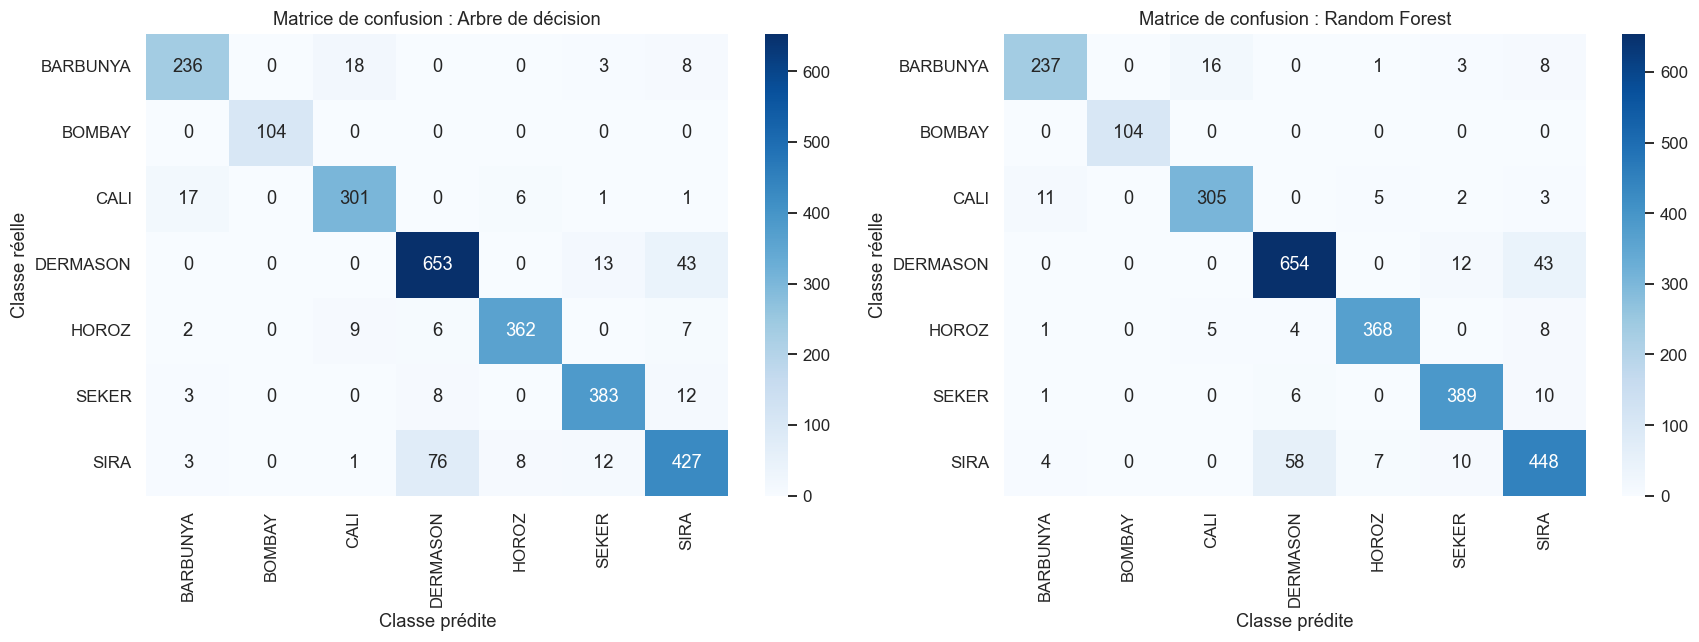

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(f"Matrice de confusion : {name}")
    ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
plt.tight_layout(); plt.show()

## 8. Comparaison des modèles et analyse des confusions

In [18]:
summary = pd.DataFrame(results).T.round(4)
summary["Hyperparamètres"] = [str(grid_dt.best_params_), str(grid_rf.best_params_)]
summary["F1 macro CV"] = [round(grid_dt.best_score_, 4), round(grid_rf.best_score_, 4)]
summary

,Accuracy,Macro F1,Weighted F1,Hyperparamètres,F1 macro CV
Arbre de décision,0.9056,0.9194,0.9053,{'clf__max_depth': 9},0.9211
Random Forest,0.9199,0.9321,0.9198,"{'clf__max_depth': None, 'clf__n_estimators': ...",0.9363


,Arbre de décision,Random Forest
BARBUNYA,0.8973,0.9133
BOMBAY,1.0000,1.0000
CALI,0.9191,0.9356
DERMASON,0.8994,0.9140
HOROZ,0.9501,0.9596
SEKER,0.9364,0.9465
SIRA,0.8332,0.8558


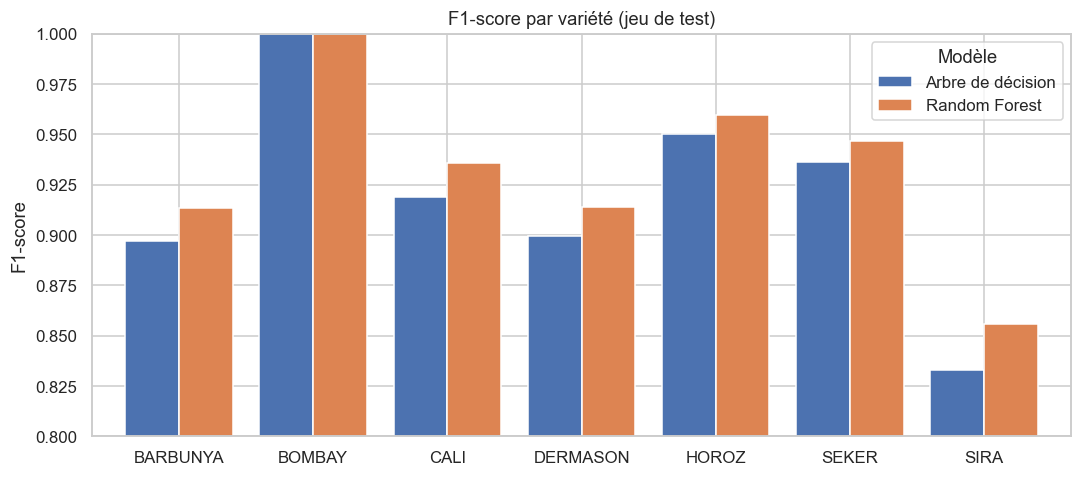

In [19]:
f1_by_class = pd.DataFrame({name: df_["f1-score"].loc[classes] for name, df_ in per_class.items()}).round(4)
display(f1_by_class)

ax = f1_by_class.plot(kind="bar", figsize=(10, 4.5), width=0.8)
ax.set_ylim(0.8, 1.0); ax.set_ylabel("F1-score")
ax.set_title("F1-score par variété (jeu de test)")
plt.xticks(rotation=0); plt.legend(title="Modèle")
plt.tight_layout(); plt.show()

In [20]:
# Paires de classes les plus confondues (hors diagonale), pour le meilleur modèle
best_name = summary["Macro F1"].idxmax()
cm = cms[best_name].copy()
np.fill_diagonal(cm, 0)

pairs = [(classes[i], classes[j], int(cm[i, j])) for i in range(len(classes))
         for j in range(len(classes)) if cm[i, j] > 0]
top_conf = pd.DataFrame(pairs, columns=["Classe réelle", "Classe prédite", "Nb d'erreurs"]) \
             .sort_values("Nb d'erreurs", ascending=False).head(8).reset_index(drop=True)
print("Meilleur modèle :", best_name)
top_conf

Meilleur modèle : Random Forest


,Classe réelle,Classe prédite,Nb d'erreurs
0,SIRA,DERMASON,58
1,DERMASON,SIRA,43
2,BARBUNYA,CALI,16
3,DERMASON,SEKER,12
4,CALI,BARBUNYA,11
5,SIRA,SEKER,10
6,SEKER,SIRA,10
7,BARBUNYA,SIRA,8


**À interpréter dans le rapport** : repérer les paires les plus confondues (le plus souvent Dermason ↔ Sira, puis Barbunya ↔ Cali), les relier à la proximité de leurs distributions sur les variables de forme (section 2.3), et noter que Bombay, bien séparée par sa taille, est quasi parfaitement reconnue.

## 9. Importance des variables (Random Forest)
Les variables étant très corrélées, l'importance est répartie entre variables redondantes : à interpréter avec prudence.

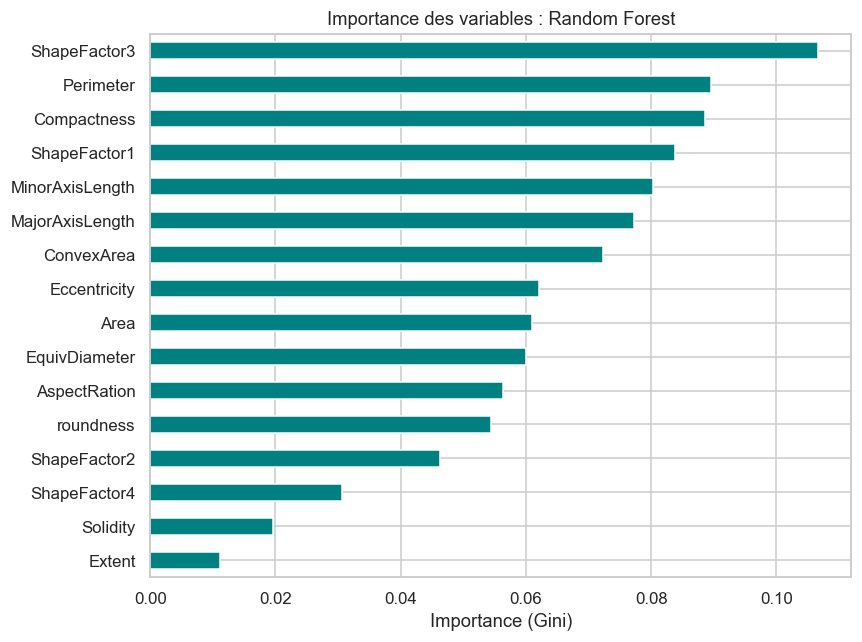

In [21]:
rf_final = grid_rf.best_estimator_.named_steps["clf"]
imp = pd.Series(rf_final.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
imp.plot(kind="barh", color="teal")
plt.title("Importance des variables : Random Forest")
plt.xlabel("Importance (Gini)")
plt.tight_layout(); plt.show()

## 10. Synthèse et export des résultats

In [22]:
import os
os.makedirs("resultats", exist_ok=True)

summary.to_csv("resultats/comparatif_dt_rf.csv")
f1_by_class.to_csv("resultats/f1_par_classe_dt_rf.csv")
std_table.to_csv("resultats/experience_standardisation.csv", index=False)

print(summary[["Accuracy", "Macro F1", "F1 macro CV"]])
print("\nFichiers exportés dans ./resultats/")

                   Accuracy  Macro F1  F1 macro CV
Arbre de décision    0.9056    0.9194       0.9211
Random Forest        0.9199    0.9321       0.9363

Fichiers exportés dans ./resultats/


### Limites à mentionner dans le rapport
1. Les variables sont extraites d'images : les variétés proches se chevauchent dans l'espace des caractéristiques.
2. Un seul split de test (seed 42) : l'écart-type de la CV donne une idée de la variabilité des estimations.
3. Les doublons éventuels peuvent légèrement gonfler les scores.
4. Grilles volontairement restreintes : `min_samples_leaf`, `max_features` ou `class_weight="balanced"` pourraient être explorés.
5. La standardisation n'a aucun effet sur les arbres : ce résultat n'est pas généralisable aux autres modèles de l'équipe (KNN, SVM, régression logistique).